# This loads generated data from **data_generation** without having to run the entire solver again

In [46]:
import sys
import importlib
from pathlib import Path

project_path = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(project_path / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import wing_surrogate.neural_network as neural_network
print("Neural network module:", neural_network.__file__)
from wing_surrogate.polynomial_regression import build_model

df = pd.read_csv(project_path / "data" / "wing_data_trial.csv")

print("Number of samples:", len(df))
df.head()

Neural network module: c:\Users\hayes\Documents\Maching-Learning-Project\src\wing_surrogate\neural_network.py
Number of samples: 500


,case_id,geometry_id,aspect_ratio,area_m2,taper_ratio,tip_twist_deg,alpha_deg,velocity,airfoil,reynolds,CL,CD,max_lift_error,runtime_s
0,0,wing_6ab2f5fbab0cb65a9b90,15.977056,9.958054,0.250503,-2.790896,2.387898,43.103690,naca0015,2.608583e+06,0.120913,0.006461,4.191092e-15,5.737345
1,1,wing_2b4b417854aa52d7e48e,15.043798,8.889915,0.353626,-0.082952,3.109294,69.090909,naca0012,3.912361e+06,0.299741,0.007467,3.885781e-15,5.614978
2,2,wing_a8e1d4a5ce305caca04d,8.012150,1.185265,0.343913,-0.412473,4.398885,52.491217,naca0015,1.491945e+06,0.356336,0.011771,4.385381e-15,5.612766
3,3,wing_36ec485db8672ba1cce1,5.491522,9.044180,0.212618,-1.473107,2.933420,69.966108,naca0015,7.010836e+06,0.178045,0.007630,4.690692e-15,5.751853
4,4,wing_26496cb3061086c26541,10.687990,6.852106,0.272507,-2.131499,5.169041,48.567956,naca0015,2.952282e+06,0.389624,0.011150,4.496403e-15,5.848093


In [47]:
input_features = [
    "aspect_ratio", "area_m2", "taper_ratio", "tip_twist_deg",
    "alpha_deg", "velocity", "airfoil",
]
output_features = ["CL", "CD"]

# Encode airfoil names so both models can use every DOE input.
X = pd.get_dummies(df[input_features], columns=["airfoil"], dtype=float)
Y = df[output_features]
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=10,
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 400
Testing samples: 100


# Polynomial Regression

In [48]:
degrees = [1, 2, 3, 4, 5]
best_testing_MSE = float("inf")
degree_results = []

for degree in degrees:
    poly_model = build_model(degree=degree)
    poly_model.fit(X_train, Y_train)

    Y_train_pred = poly_model.predict(X_train)
    Y_test_pred = poly_model.predict(X_test)

    training_MSE = np.mean((Y_train_pred - Y_train.to_numpy()) ** 2)
    testing_MSE = np.mean((Y_test_pred - Y_test.to_numpy()) ** 2)
    degree_results.append({
        "Degree": degree,
        "Training MSE": training_MSE,
        "Testing MSE": testing_MSE,
    })

    if testing_MSE < best_testing_MSE:
        best_testing_MSE = testing_MSE
        best_degree = degree
        model = poly_model

Y_train_pred = model.predict(X_train)
Y_test_pred = model.predict(X_test)

print("Selected polynomial degree:", best_degree)
pd.DataFrame(degree_results)


Selected polynomial degree: 4


,Degree,Training MSE,Testing MSE
0,1,6.826842e-05,8.045084e-05
1,2,5.445222e-06,8.259303e-06
2,3,4.332434e-07,9.855838e-07
3,4,3.079792e-08,8.625757e-07
4,5,2.334946e-31,1.260832e-06


# Polynomial Regression Plots

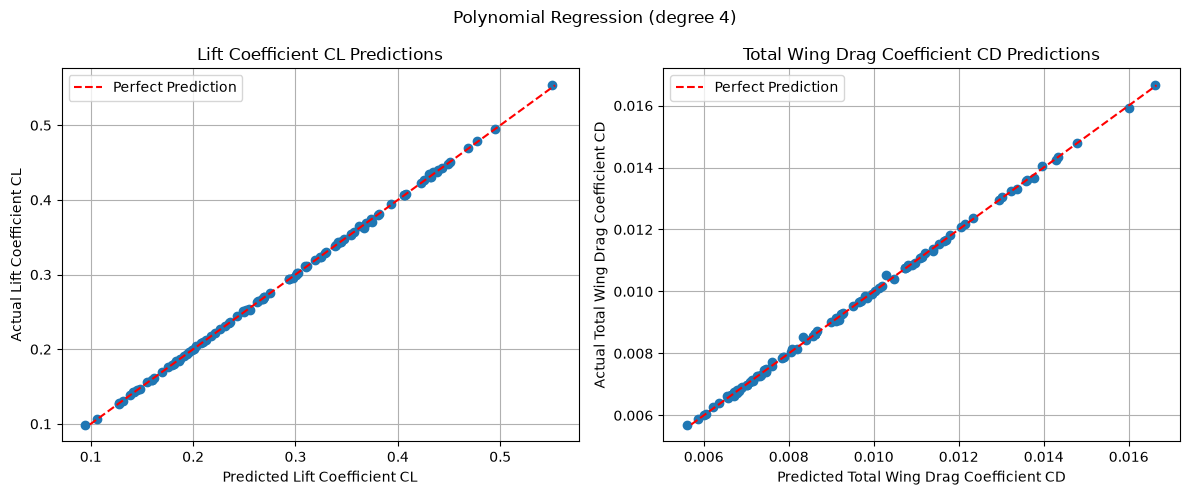

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(f"Polynomial Regression (degree {best_degree})")

labels = ["Lift Coefficient CL", "Total Wing Drag Coefficient CD"]
for i, (ax, label) in enumerate(zip(axes, labels)):
    actual = Y_test.iloc[:, i].to_numpy()
    ax.plot(Y_test_pred[:, i], actual, "o")
    ax.plot(
        [actual.min(), actual.max()],
        [actual.min(), actual.max()],
        "r--", label="Perfect Prediction",
    )
    ax.set_xlabel(f"Predicted {label}")
    ax.set_ylabel(f"Actual {label}")
    ax.set_title(f"{label} Predictions")
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()


# Neural Network Test

In [50]:
torch.manual_seed(10)

X_temp, X_test, Y_temp, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=10,
)

X_train, X_val, Y_train, Y_val = train_test_split(
    X_temp, Y_temp, test_size=0.20, random_state=10,
)

X_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_val_scaled = X_scaler.transform(X_val)
X_test_scaled = X_scaler.transform(X_test)

Y_scaler = StandardScaler()
Y_train_scaled = Y_scaler.fit_transform(Y_train)
Y_val_scaled = Y_scaler.transform(Y_val)

In [51]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

Y_train_tensor = torch.tensor(Y_train_scaled, dtype=torch.float32)
Y_val_tensor = torch.tensor(Y_val_scaled, dtype=torch.float32)

Sequential(
  (0): Linear(in_features=8, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=2, bias=True)
)
Epoch 100, Training Loss: 0.001500, Validation Loss: 0.004110
Epoch 200, Training Loss: 0.000675, Validation Loss: 0.002828
Epoch 300, Training Loss: 0.000475, Validation Loss: 0.002531
Epoch 400, Training Loss: 0.000459, Validation Loss: 0.002598
Epoch 500, Training Loss: 0.000367, Validation Loss: 0.002211
Epoch 600, Training Loss: 0.000432, Validation Loss: 0.002123
Epoch 700, Training Loss: 0.000507, Validation Loss: 0.002155
Epoch 800, Training Loss: 0.000392, Validation Loss: 0.002094
Epoch 900, Training Loss: 0.000282, Validation Loss: 0.002296
Epoch 1000, Training Loss: 0.000178, Validation Loss: 0.002102


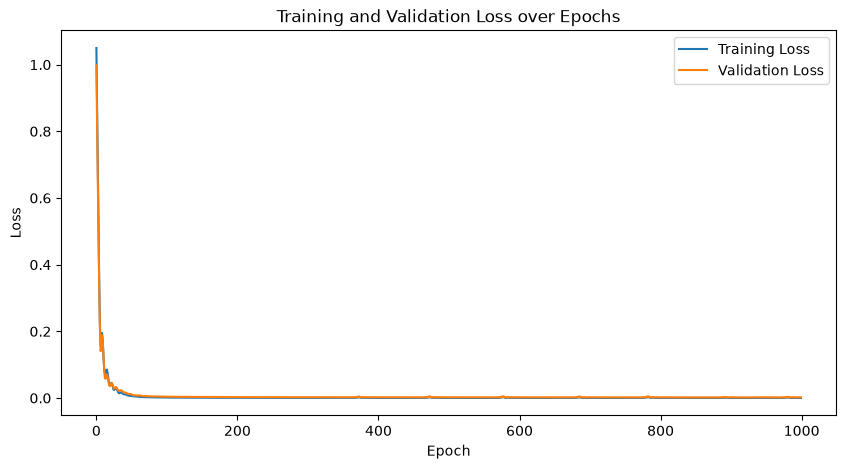

In [52]:
torch.manual_seed(10)

# Reload edits to neural_network.py before building a new model.
importlib.reload(neural_network)
nn_model = neural_network.build_model(input_size=X_train.shape[1], output_size=len(output_features))
print(nn_model)

loss_fun = nn.MSELoss()
optimizer = torch.optim.Adam(nn_model.parameters(), lr=0.02)

Epoch = 1000
train_Losses = []
val_Losses = []

for epoch in range(Epoch):

    nn_model.train()

    Y_pred = nn_model(X_train_tensor)
    Y_val_pred = nn_model(X_val_tensor)

    loss = loss_fun(Y_pred, Y_train_tensor)
    loss_val = loss_fun(Y_val_pred, Y_val_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_Losses.append(loss.item())
    val_Losses.append(loss_val.item())

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}, Training Loss: {loss.item():.6f}, Validation Loss: {loss_val.item():.6f}")

plt.figure(figsize=(10, 5))
plt.plot(train_Losses, label="Training Loss")
plt.plot(val_Losses, label="Validation Loss")
plt.title("Training and Validation Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [53]:
nn_model.eval()

with torch.no_grad():
    Y_train_nn_scaled = nn_model(X_train_tensor).numpy()
    Y_test_nn_scaled = nn_model(X_test_tensor).numpy()

Y_train_nn_pred = Y_scaler.inverse_transform(Y_train_nn_scaled)
Y_test_nn_pred = Y_scaler.inverse_transform(Y_test_nn_scaled)

# Neural Network Plots

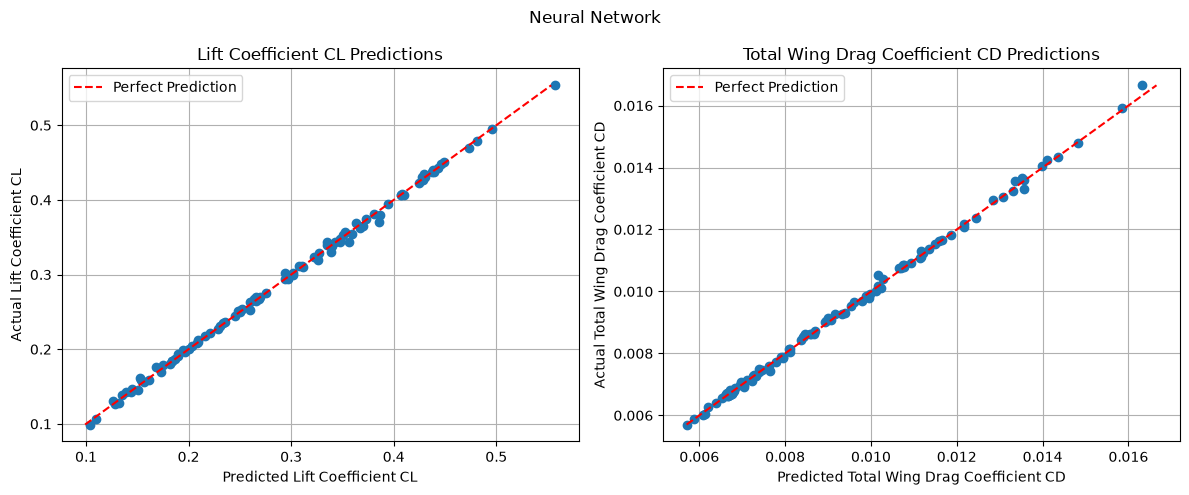

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Neural Network")

labels = ["Lift Coefficient CL", "Total Wing Drag Coefficient CD"]
for i, (ax, label) in enumerate(zip(axes, labels)):
    actual = Y_test.iloc[:, i].to_numpy()
    ax.plot(Y_test_nn_pred[:, i], actual, "o")
    ax.plot(
        [actual.min(), actual.max()],
        [actual.min(), actual.max()],
        "r--", label="Perfect Prediction",
    )
    ax.set_xlabel(f"Predicted {label}")
    ax.set_ylabel(f"Actual {label}")
    ax.set_title(f"{label} Predictions")
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()


# Model Comparison

RMSE and MAE use the held-out test samples and the original coefficient scale.


In [55]:
results = []

for model_name, predictions in [
    (f"Polynomial (degree {best_degree})", Y_test_pred),
    ("Neural Network", Y_test_nn_pred),
]:
    for i, output in enumerate(output_features):
        errors = predictions[:, i] - Y_test.iloc[:, i].to_numpy()
        results.append({
            "Model": model_name,
            "Output": output,
            "RMSE": np.sqrt(np.mean(errors ** 2)),
            "MAE": np.mean(np.abs(errors)),
        })

comparison_table = pd.DataFrame(results)
comparison_table


,Model,Output,RMSE,MAE
0,Polynomial (degree 4),CL,0.001312,0.000874
1,Polynomial (degree 4),CD,0.000051,0.000035
2,Neural Network,CL,0.003838,0.002813
3,Neural Network,CD,0.000095,0.000071
